**Load Data** 

We loaded the dataset and checked its size (1,382 days and 20 columns).

In [1]:
import pandas as pd

df=pd.read_csv('Dataset_Fixed.csv')
print(df.head())
print(df.shape)

   Unnamed: 0  Average Outflow  Average Inflow  Energy Consumption  Ammonia  \
0           0            2.941           2.589            175856.0     27.0   
1           1            2.936           2.961            181624.0     25.0   
2           2            2.928           3.225            202016.0     42.0   
3           3            2.928           3.354            207547.0     36.0   
4           4            2.917           3.794            202824.0     46.0   

   Biological Oxygen Demand  Chemical Oxygen Demand  Total Nitrogen  \
0                     365.0                   730.0          60.378   
1                     370.0                   740.0          60.026   
2                     418.0                   836.0          64.522   
3                     430.0                   850.0          63.000   
4                     508.0                  1016.0          65.590   

   Average Temperature  Maximum temperature  Minimum temperature  \
0                 19.3        

**Tidy the Table** 

We removed the index column, combined Year, Month and Day into one `Date` column, and sorted the rows by date, because the model must learn from past days and be tested on later days.

In [2]:
df = df.drop(columns=['Unnamed: 0'])

*Sorting by Dates*

In [3]:
date_parts = df[["Year", "Month", "Day"]].rename(
    columns={"Year": "year", "Month": "month", "Day": "day"}
).astype(int)
df['Date'] = pd.to_datetime(date_parts) 
df = df.sort_values(by='Date').reset_index(drop=True)

print(df[['Date', 'Energy Consumption']].head())

        Date  Energy Consumption
0 2014-01-01            175856.0
1 2014-01-02            181624.0
2 2014-01-05            202016.0
3 2014-01-06            207547.0
4 2014-01-07            202824.0


**Data Cleaning** 

We applied the same rules as in the EDA: atmospheric pressure was dropped, and physically impossible values (zeros in temperature, humidity and visibility, visibility above 100 km, near-zero outflow and one-day nitrogen spikes) were set to missing without deleting any rows.

In [4]:
import numpy as np

#Based on the data, eliminate the columns which is impossible to have 0 values
df = df.drop(columns=["Atmospheric pressure"])

#Columns with 0 values are likely to be missing data, so we will replace them with NaN
zero_is_missing = ["Average visibility","Maximum temperature","Average Temperature","Average humidity"]
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)

#Checking the number of missing values in each column
print(df[zero_is_missing].isna().sum())

#Row with at least one missing value 
print("Row affected by missing values:", df[zero_is_missing].isna().any(axis=1).sum())

Average visibility     277
Maximum temperature     10
Average Temperature      5
Average humidity         5
dtype: int64
Row affected by missing values: 282


In [5]:
import numpy as np

# Visibility above 100 km is impossible: set those 2 values to missing
df.loc[df["Average visibility"] > 100, "Average visibility"] = np.nan

# Near-zero outflow (< 0.1 m3/s) while the plant was running: sensor failure -> missing
df.loc[df["Average Outflow"] < 0.1, "Average Outflow"] = np.nan

# Isolated one-day nitrogen spikes (> 80 mg/L, neighbors are about 64) -> missing
df.loc[df["Total Nitrogen"] > 80, "Total Nitrogen"] = np.nan

print(df.isna().sum())

Average Outflow              24
Average Inflow                0
Energy Consumption            0
Ammonia                       0
Biological Oxygen Demand      0
Chemical Oxygen Demand        0
Total Nitrogen                2
Average Temperature           5
Maximum temperature          10
Minimum temperature           0
Average humidity              5
Total rainfall                0
Average visibility          279
Average wind speed            0
Maximum wind speed            0
Year                          0
Month                         0
Day                           0
Date                          0
dtype: int64


**Target** 

We converted daily energy consumption from kWh/day to MWh/day, which is the variable the models will predict.

In [6]:
df["Energy (MWh/day)"] = df["Energy Consumption"] / 1000
print(df["Energy (MWh/day)"].mean())

275.1590890014472


**FEATURED ENGINEERING**

**Log of Inflow** 

Because inflow is strongly right-skewed, we used its logarithm, which reduced the skewness from 3.75 to 1.65.

In [7]:
df["log_inflow"] = np.log(df["Average Inflow"])

print(df["Average Inflow"].skew())
print(df["log_inflow"].skew())

3.7518645063320086
1.652146086985599


**Rain Day** 

Because rainfall is zero on 92% of days, we created a simple yes/no feature (1 = rain, 0 = no rain).

In [8]:
df["rain_day"] = (df["Total rainfall"] > 0).astype(int)
print(df["rain_day"].mean())

0.0788712011577424


**Cyclical Month Encoding** 

We encoded the month with sine and cosine, so that December and January are next to each other instead of 11 units apart.

In [9]:
df["month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["Month"] /12)
print(df.groupby("Month")[["month_sin", "month_cos"]].first().round(2))

       month_sin  month_cos
Month                      
1.0         0.50       0.87
2.0         0.87       0.50
3.0         1.00       0.00
4.0         0.87      -0.50
5.0         0.50      -0.87
6.0         0.00      -1.00
7.0        -0.50      -0.87
8.0        -0.87      -0.50
9.0        -1.00      -0.00
10.0       -0.87       0.50
11.0       -0.50       0.87
12.0       -0.00       1.00


**Day of Week:** 

We added the day of the week (0 = Monday, 6 = Sunday), noting that Fridays and Saturdays are mostly missing from the dataset.

In [10]:
df["day_of_week"] = df["Date"].dt.dayofweek
print(df.groupby("day_of_week")["Energy (MWh/day)"].agg(["mean", "count"]))

                   mean  count
day_of_week                   
0            270.155085    272
1            277.869853    279
2            273.920033    275
3            285.544695    266
4            257.661909     33
5            248.756600      5
6            270.763750    252


**Train/Test Split** 

Because the data is a time series, we split it by date instead of randomly: 2014–2017 for training (1,016 days) and January 2018–June 2019 for testing (366 days).

In [11]:
train = df[df["Date"] < "2018-01-01"]
test = df[df["Date"] >= "2018-01-01"]

print(len(train), len(test))

1016 366


**Baselines** 

Following Tutorial 4, we built dummy models that always predict the training mean or median, which any useful model must beat.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, max_error, mean_absolute_percentage_error

RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

TARGET = "Energy (MWh/day)"
FEATURES = ["log_inflow", "Biological Oxygen Demand", "Ammonia", "Total Nitrogen",
            "Maximum temperature", "Average humidity", "rain_day",
            "month_sin", "month_cos", "day_of_week"]

# Tutorial 4
def get_regression_metrics(model, X, y_true):
    y_predicted = model.predict(X)
    return {
        "mae": mean_absolute_error(y_true, y_predicted),
        "mse": mean_squared_error(y_true, y_predicted),
        "max_error": max_error(y_true, y_predicted),
        "mape": mean_absolute_percentage_error(y_true, y_predicted),
    }

# Baselines: always predict the training mean or the training median
dummyregressor_mean = DummyRegressor(strategy="mean")
dummyregressor_median = DummyRegressor(strategy="median")
dummyregressor_mean.fit(train[FEATURES], train[TARGET])
dummyregressor_median.fit(train[FEATURES], train[TARGET])

for name, model in [("mean", dummyregressor_mean), ("median", dummyregressor_median)]:
    print(name, "(Test):", get_regression_metrics(model, test[FEATURES], test[TARGET]))

mean (Test): {'mae': 33.131960500839035, 'mse': 1713.1261899184465, 'max_error': 114.8186909448819, 'mape': 0.12214058674649682}
median (Test): {'mae': 33.16690983606557, 'mse': 1716.2892399603827, 'max_error': 114.6055, 'mape': 0.12217319775731299}


**Ridge Regression** 

We built a pipeline that fills missing values with the training median, standardizes the features, and fits a Ridge regression model.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Pipeline: fill missing values -> scaling -> ridge (same style as Tutorial 4, section 7.1)
pipe_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # fill NaN with the training median
    ("scaling", StandardScaler()),                   # mean 0, standard deviation 1
    ("ridge", Ridge(alpha=1)),                       # default regularization for now
])

pipe_ridge.fit(train[FEATURES], train[TARGET])

print("Ridge (Train):", get_regression_metrics(pipe_ridge, train[FEATURES], train[TARGET]))
print("Ridge (Test):", get_regression_metrics(pipe_ridge, test[FEATURES], test[TARGET]))

Ridge (Train): {'mae': 31.11015656553766, 'mse': 1600.540462883909, 'max_error': 161.1780173248159, 'mape': 0.12139023448758691}
Ridge (Test): {'mae': 34.09661356250218, 'mse': 1911.0635115658079, 'max_error': 133.39553169882288, 'mape': 0.12660909701416184}


**Ridge Tuning** 

We tuned the regularization strength (alpha) with grid search and 5-fold time-series cross-validation, which always validates on data that comes after the training folds.

In [15]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)   # time-ordered CV folds (instead of cv=5)

# Values of alpha to try, on a log scale (as in Tutorial 4, section 8.1)
param_grid = {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}

grid_ridge = GridSearchCV(pipe_ridge, param_grid=param_grid, cv=tscv,
                          scoring="neg_mean_absolute_error")
grid_ridge.fit(train[FEATURES], train[TARGET])

print("Best alpha:", grid_ridge.best_params_)
print("Best CV MAE:", -grid_ridge.best_score_)
print("Tuned Ridge (Test):", get_regression_metrics(grid_ridge.best_estimator_, test[FEATURES], test[TARGET]))

Best alpha: {'ridge__alpha': 1000}
Best CV MAE: 34.652555306003414
Tuned Ridge (Test): {'mae': 33.12078829981599, 'mse': 1759.549842614344, 'max_error': 125.93810339272255, 'mape': 0.12258583689014889}


**Random Forest** 

We tuned a random forest, which can capture nonlinear relationships; it does not need feature scaling, but missing values are still filled with the training median.

In [16]:
from sklearn.ensemble import RandomForestRegressor

pipe_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1)),
])

# Hyperparameters to tune
param_grid_rf = {
    "rf__max_depth": [3, 5, 8, None],        # how deep each tree can grow
    "rf__min_samples_leaf": [1, 5, 20],      # minimum days in each final leaf
}

grid_rf = GridSearchCV(pipe_rf, param_grid=param_grid_rf, cv=tscv,
                       scoring="neg_mean_absolute_error")
grid_rf.fit(train[FEATURES], train[TARGET])

print("Best params:", grid_rf.best_params_)
print("Best CV MAE:", -grid_rf.best_score_)
print("Tuned RF (Test):", get_regression_metrics(grid_rf.best_estimator_, test[FEATURES], test[TARGET]))

Best params: {'rf__max_depth': None, 'rf__min_samples_leaf': 5}
Best CV MAE: 36.779722301081264
Tuned RF (Test): {'mae': 32.35347723285559, 'mse': 1697.1481435599112, 'max_error': 145.2619458364813, 'mape': 0.12138867983208555}


**Gradient Boosting:** 

We tuned a gradient boosting model, in which each new tree corrects the errors of the previous trees.

In [17]:
from sklearn.ensemble import GradientBoostingRegressor

pipe_gb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("gb", GradientBoostingRegressor(random_state=RANDOM_SEED)),
])

# Hyperparameters to tune
param_grid_gb = {
    "gb__learning_rate": [0.03, 0.1],   # how strongly each new tree corrects the previous ones
    "gb__max_depth": [2, 3],            # depth of each tree (boosting uses shallow trees)
    "gb__n_estimators": [100, 300],     # number of trees
}

grid_gb = GridSearchCV(pipe_gb, param_grid=param_grid_gb, cv=tscv,
                       scoring="neg_mean_absolute_error")
grid_gb.fit(train[FEATURES], train[TARGET])

print("Best params:", grid_gb.best_params_)
print("Best CV MAE:", -grid_gb.best_score_)
print("Tuned GB (Test):", get_regression_metrics(grid_gb.best_estimator_, test[FEATURES], test[TARGET]))

Best params: {'gb__learning_rate': 0.03, 'gb__max_depth': 3, 'gb__n_estimators': 300}
Best CV MAE: 36.02264901910401
Tuned GB (Test): {'mae': 32.15649184666465, 'mse': 1693.3685612854013, 'max_error': 139.02928839066197, 'mape': 0.12066310595674105}


**Model Comparison** 

We collected the test-set metrics of all baselines and models in one table.

In [18]:
models_to_compare = {
    "Baseline (mean)": dummyregressor_mean,
    "Baseline (median)": dummyregressor_median,
    "Ridge (alpha=1)": pipe_ridge,
    "Ridge (tuned)": grid_ridge.best_estimator_,
    "Random Forest (tuned)": grid_rf.best_estimator_,
    "Gradient Boosting (tuned)": grid_gb.best_estimator_,
}

test_results = {}
for name, model in models_to_compare.items():
    test_results[name] = get_regression_metrics(model, test[FEATURES], test[TARGET])

results_table = pd.DataFrame(test_results).T            # .T = flip rows and columns
results_table["rmse"] = results_table["mse"] ** 0.5     # add RMSE (same unit as energy)
print(results_table.round(3))

                              mae       mse  max_error   mape    rmse
Baseline (mean)            33.132  1713.126    114.819  0.122  41.390
Baseline (median)          33.167  1716.289    114.606  0.122  41.428
Ridge (alpha=1)            34.097  1911.064    133.396  0.127  43.716
Ridge (tuned)              33.121  1759.550    125.938  0.123  41.947
Random Forest (tuned)      32.353  1697.148    145.262  0.121  41.196
Gradient Boosting (tuned)  32.156  1693.369    139.029  0.121  41.151


**Model B** 

We retrained Ridge, random forest and gradient boosting with the same pipelines and grids, now including the two lag features.

**Lag Features** 

We added the energy consumption of the previous recorded day (`energy_prev`) and the mean of the previous 7 recorded days (`energy_prev7`), using only past values to avoid data leakage, and then split the data again so that both sets include these new columns.

In [19]:
# Lag features: only use PAST energy values (shift(1) = previous recorded day)
df["energy_prev"] = df[TARGET].shift(1)
df["energy_prev7"] = df[TARGET].shift(1).rolling(7, min_periods=3).mean()   # mean of the previous 7 recorded days

# Split again so train and test include the new columns
train = df[df["Date"] < "2018-01-01"]
test = df[df["Date"] >= "2018-01-01"]

FEATURES_B = FEATURES + ["energy_prev", "energy_prev7"]
print(train[["Date", TARGET, "energy_prev", "energy_prev7"]].head(10))

        Date  Energy (MWh/day)  energy_prev  energy_prev7
0 2014-01-01           175.856          NaN           NaN
1 2014-01-02           181.624      175.856           NaN
2 2014-01-05           202.016      181.624           NaN
3 2014-01-06           207.547      202.016    186.498667
4 2014-01-07           202.824      207.547    191.760750
5 2014-01-08           247.691      202.824    193.973400
6 2014-01-09           224.706      247.691    202.926333
7 2014-01-12           212.440      224.706    206.037714
8 2014-01-13           202.676      212.440    211.264000
9 2014-01-14           202.411      202.676    214.271429


**Persistence Baseline** 

Because the new features use past energy values, we added a second baseline that predicts today's energy as the energy of the previous recorded day, so Model B can be compared against a fair reference.

In [20]:
# Persistence baseline: predict today's energy = previous recorded day's energy
persistence_pred = test["energy_prev"]
print("Persistence MAE:", mean_absolute_error(test[TARGET], persistence_pred))
print("Persistence RMSE:", mean_squared_error(test[TARGET], persistence_pred) ** 0.5)

Persistence MAE: 31.312155737704916
Persistence RMSE: 42.8412608779755


In [21]:
searches_B = {
    "Ridge (B)": GridSearchCV(pipe_ridge, param_grid, cv=tscv, scoring="neg_mean_absolute_error"),
    "Random Forest (B)": GridSearchCV(pipe_rf, param_grid_rf, cv=tscv, scoring="neg_mean_absolute_error"),
    "Gradient Boosting (B)": GridSearchCV(pipe_gb, param_grid_gb, cv=tscv, scoring="neg_mean_absolute_error"),
}

for name, search in searches_B.items():
    search.fit(train[FEATURES_B], train[TARGET])
    print(name, "| best:", search.best_params_, "| CV MAE:", round(-search.best_score_, 2))
    print("   Test:", get_regression_metrics(search.best_estimator_, test[FEATURES_B], test[TARGET]))

Ridge (B) | best: {'ridge__alpha': 10} | CV MAE: 27.25
   Test: {'mae': 27.805900367618502, 'mse': 1327.6219758248787, 'max_error': 120.76548856987085, 'mape': 0.10435412821127489}
Random Forest (B) | best: {'rf__max_depth': 5, 'rf__min_samples_leaf': 20} | CV MAE: 27.99
   Test: {'mae': 26.91129387843886, 'mse': 1290.166469872095, 'max_error': 123.2859888307458, 'mape': 0.10171954785181332}
Gradient Boosting (B) | best: {'gb__learning_rate': 0.03, 'gb__max_depth': 2, 'gb__n_estimators': 300} | CV MAE: 27.36
   Test: {'mae': 26.965871393913524, 'mse': 1275.59048310039, 'max_error': 126.87386193915836, 'mape': 0.1015146700587233}


**Model Comparison (B)**

In [23]:
# Each model is stored together with the feature set it was trained on
models_to_compare = {
    "Baseline (mean)": (dummyregressor_mean, FEATURES),
    "Baseline (median)": (dummyregressor_median, FEATURES),
    "Ridge (alpha=1)": (pipe_ridge, FEATURES),
    "Ridge (tuned)": (grid_ridge.best_estimator_, FEATURES),
    "Random Forest (tuned)": (grid_rf.best_estimator_, FEATURES),
    "Gradient Boosting (tuned)": (grid_gb.best_estimator_, FEATURES),
    "Ridge (B)": (searches_B["Ridge (B)"].best_estimator_, FEATURES_B),
    "Random Forest (B)": (searches_B["Random Forest (B)"].best_estimator_, FEATURES_B),
    "Gradient Boosting (B)": (searches_B["Gradient Boosting (B)"].best_estimator_, FEATURES_B),
}

test_results = {}
for name, (model, features) in models_to_compare.items():
    test_results[name] = get_regression_metrics(model, test[features], test[TARGET])

results_table = pd.DataFrame(test_results).T            # .T = flip rows and columns

# Persistence baseline is not an sklearn model, so its row is added separately
results_table.loc["Baseline (previous day)", "mae"] = mean_absolute_error(test[TARGET], test["energy_prev"])
results_table.loc["Baseline (previous day)", "mse"] = mean_squared_error(test[TARGET], test["energy_prev"])

results_table["rmse"] = results_table["mse"] ** 0.5     # RMSE in MWh/day
base_mae = results_table.loc["Baseline (mean)", "mae"]
results_table["mae vs mean baseline (%)"] = 100 * (results_table["mae"] - base_mae) / base_mae   # negative = better

results_table = results_table.sort_values("mae")        # best model at the top
results_table.to_csv("results_table.csv")               # save for the paper
results_table.round(3)

,mae,mse,max_error,mape,rmse,mae vs mean baseline (%)
Random Forest (B),26.911,1290.166,123.286,0.102,35.919,-18.775
Gradient Boosting (B),26.966,1275.590,126.874,0.102,35.715,-18.611
Ridge (B),27.806,1327.622,120.765,0.104,36.437,-16.075
Baseline (previous day),31.312,1835.374,NaN,NaN,42.841,-5.493
Gradient Boosting (tuned),32.156,1693.369,139.029,0.121,41.151,-2.944
Random Forest (tuned),32.353,1697.148,145.262,0.121,41.196,-2.350
Ridge (tuned),33.121,1759.550,125.938,0.123,41.947,-0.034
Baseline (mean),33.132,1713.126,114.819,0.122,41.390,0.000
Baseline (median),33.167,1716.289,114.606,0.122,41.428,0.105
Ridge (alpha=1),34.097,1911.064,133.396,0.127,43.716,2.912


**Cross-Validation MAE** 

We added the mean cross-validation MAE of each tuned model; the final model is chosen by the lowest CV MAE on the training data, not by the test score.

In [24]:
# CV MAE is stored by GridSearchCV in best_score_ (negative, so we multiply by -1)
all_searches = {
    "Ridge (tuned)": grid_ridge,
    "Random Forest (tuned)": grid_rf,
    "Gradient Boosting (tuned)": grid_gb,
    "Ridge (B)": searches_B["Ridge (B)"],
    "Random Forest (B)": searches_B["Random Forest (B)"],
    "Gradient Boosting (B)": searches_B["Gradient Boosting (B)"],
}

for name, search in all_searches.items():
    results_table.loc[name, "cv mae"] = -search.best_score_

results_table.to_csv("results_table.csv")
results_table[["cv mae", "mae", "rmse", "mae vs mean baseline (%)"]].round(2)

,cv mae,mae,rmse,mae vs mean baseline (%)
Random Forest (B),27.99,26.91,35.92,-18.78
Gradient Boosting (B),27.36,26.97,35.72,-18.61
Ridge (B),27.25,27.81,36.44,-16.08
Baseline (previous day),NaN,31.31,42.84,-5.49
Gradient Boosting (tuned),36.02,32.16,41.15,-2.94
Random Forest (tuned),36.78,32.35,41.20,-2.35
Ridge (tuned),34.65,33.12,41.95,-0.03
Baseline (mean),NaN,33.13,41.39,0.00
Baseline (median),NaN,33.17,41.43,0.11
Ridge (alpha=1),NaN,34.10,43.72,2.91


**Feature importance** 

We used permutation importance on the test set, which shuffles one feature at a time and measures how much the MAE increases. We applied it to random forest (A) and gradient boosting (A) to see which influent, hydraulic and weather variables matter most, and to Ridge (B), the model with the lowest CV MAE.

Random Forest (A)
month_sin                   1.89
Total Nitrogen              1.52
log_inflow                  1.24
day_of_week                 0.42
Biological Oxygen Demand    0.12
rain_day                    0.00
Average humidity           -0.16
Ammonia                    -0.43
Maximum temperature        -0.45
month_cos                  -0.53
dtype: float64 

Gradient Boosting (A)
Total Nitrogen              1.75
log_inflow                  0.87
month_sin                   0.87
day_of_week                 0.50
Biological Oxygen Demand    0.17
rain_day                   -0.00
Ammonia                    -0.17
month_cos                  -0.23
Average humidity           -0.30
Maximum temperature        -0.48
dtype: float64 

Ridge (B)
energy_prev                 4.81
energy_prev7                1.51
month_sin                   0.19
day_of_week                 0.10
month_cos                   0.08
log_inflow                  0.07
Maximum temperature         0.06
Ammonia                  

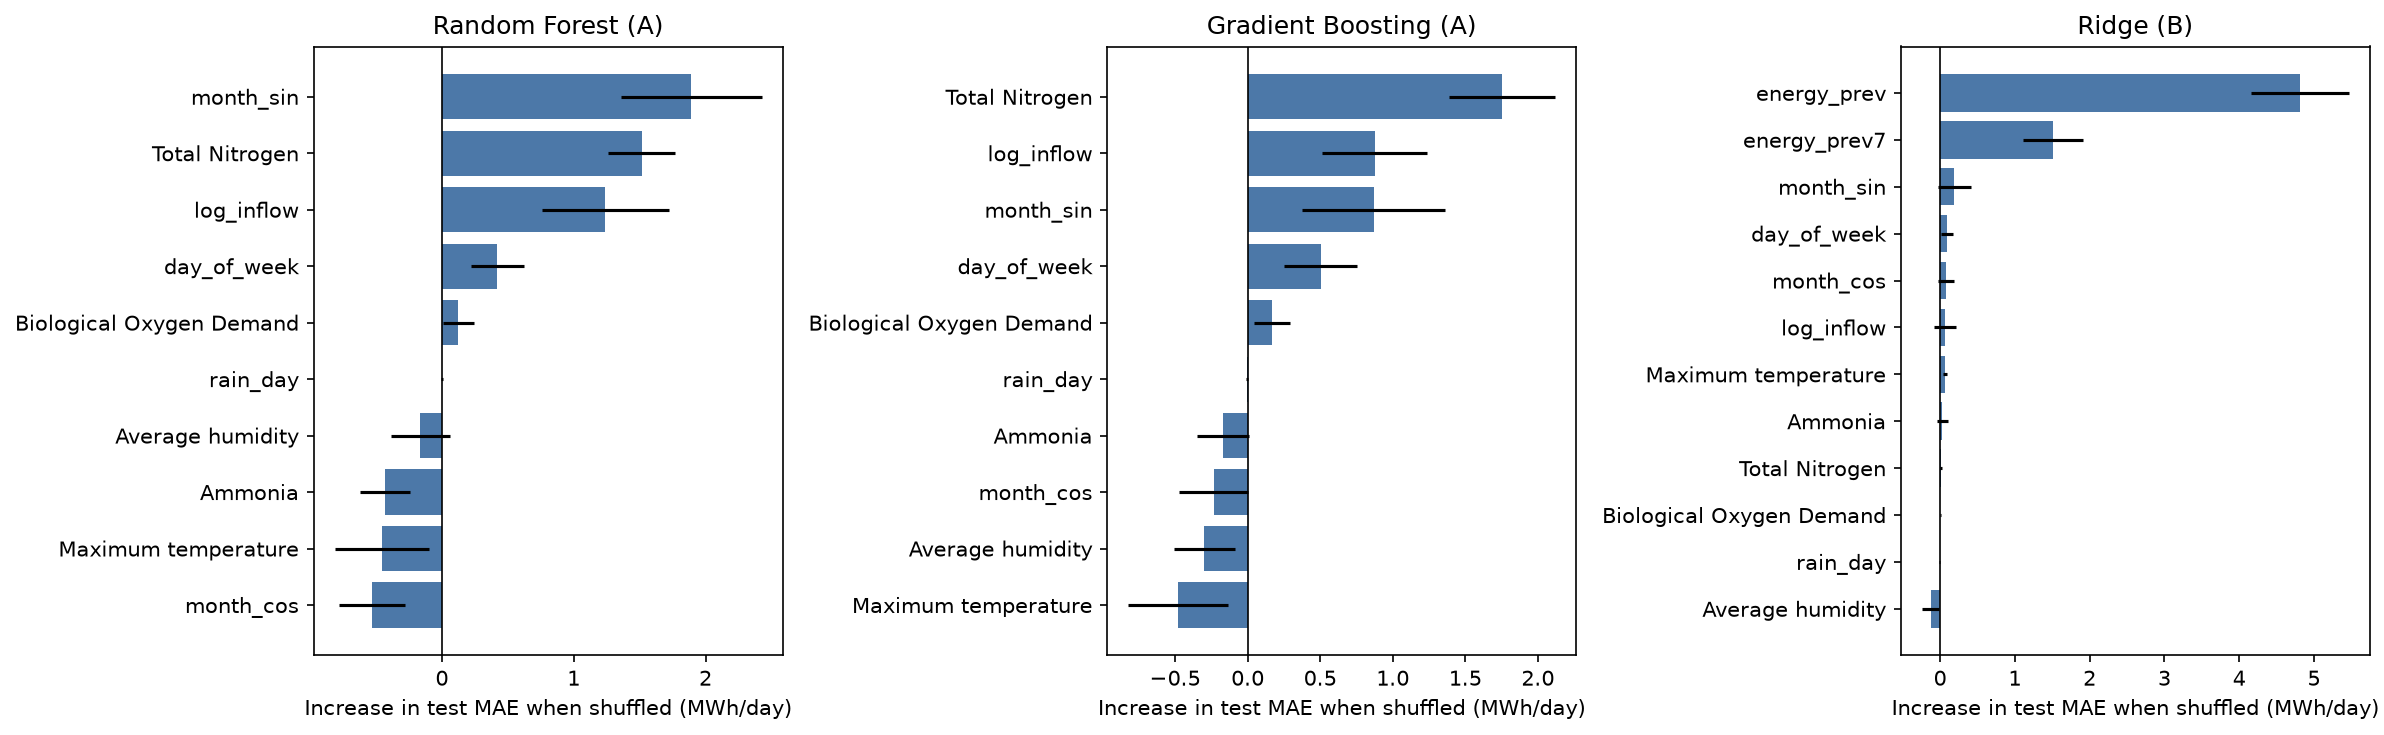

In [26]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

models_for_importance = {
    "Random Forest (A)": (grid_rf.best_estimator_, FEATURES),        # CHANGED: added RF (A)
    "Gradient Boosting (A)": (grid_gb.best_estimator_, FEATURES),
    "Ridge (B)": (searches_B["Ridge (B)"].best_estimator_, FEATURES_B),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)            # CHANGED: 3 panels, wider figure

for ax, (name, (model, features)) in zip(axes, models_for_importance.items()):
    # Shuffle each feature 20 times and measure how much the test MAE increases
    result = permutation_importance(model, test[features], test[TARGET], n_repeats=20,
                                    random_state=RANDOM_SEED, scoring="neg_mean_absolute_error")
    importance = pd.Series(result.importances_mean, index=features).sort_values()
    error = pd.Series(result.importances_std, index=features)[importance.index]

    ax.barh(importance.index, importance.values, xerr=error.values, color="#4C78A8")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Increase in test MAE when shuffled (MWh/day)")
    ax.set_title(name)
    print(name)
    print(importance.sort_values(ascending=False).round(2), "\n")

plt.tight_layout()
plt.savefig("fig_permutation_importance.png", bbox_inches="tight")
plt.show()

**Predictions Over Time** 

We plotted the actual daily energy consumption in the test period together with the predictions of the best Model A (gradient boosting) and the best Model B (Ridge).

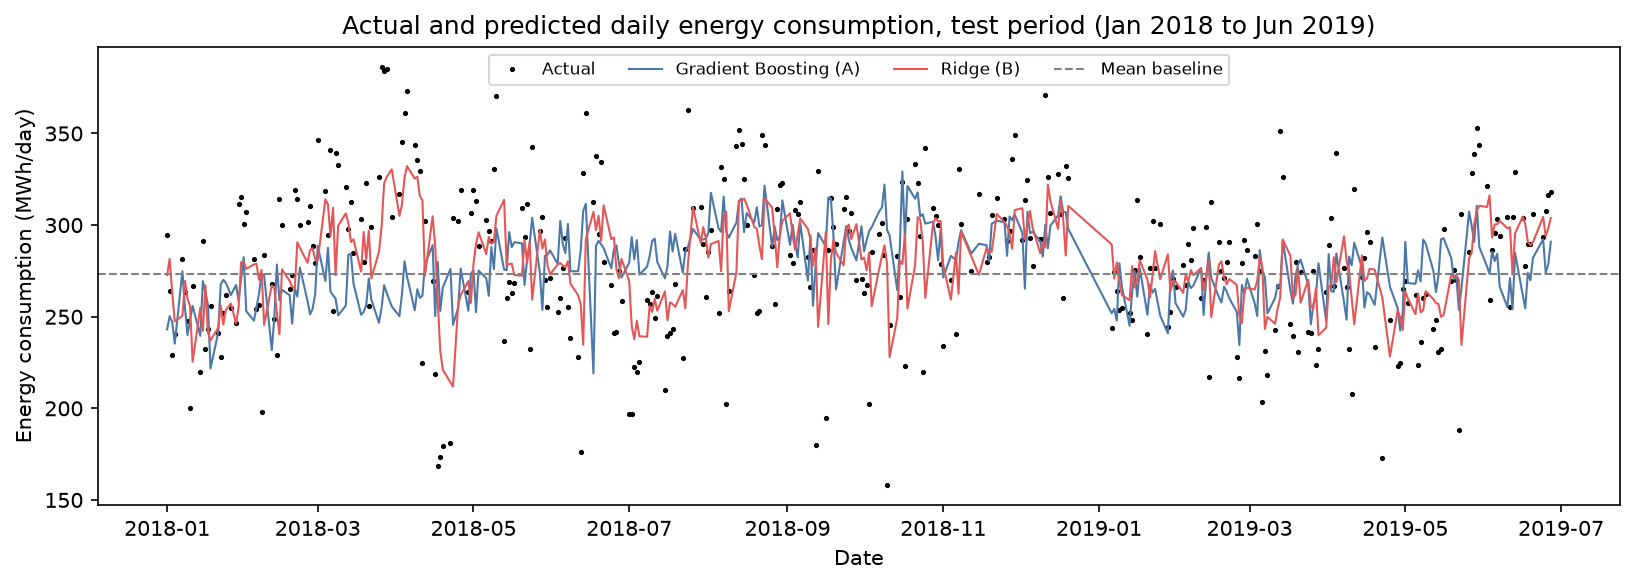

In [27]:
# Best Model A that uses the features (GB) and best Model B by CV (Ridge)
pred_A = grid_gb.best_estimator_.predict(test[FEATURES])
pred_B = searches_B["Ridge (B)"].best_estimator_.predict(test[FEATURES_B])

fig, ax = plt.subplots(figsize=(11, 4), dpi=150)
ax.plot(test["Date"], test[TARGET], ".", markersize=3, color="black", label="Actual")
ax.plot(test["Date"], pred_A, "-", linewidth=1, color="#4C78A8", label="Gradient Boosting (A)")
ax.plot(test["Date"], pred_B, "-", linewidth=1, color="#E45756", label="Ridge (B)")
ax.axhline(train[TARGET].mean(), color="grey", linestyle="--", linewidth=1, label="Mean baseline")

ax.set_xlabel("Date")
ax.set_ylabel("Energy consumption (MWh/day)")
ax.set_title("Actual and predicted daily energy consumption, test period (Jan 2018 to Jun 2019)")
ax.legend(fontsize=8, ncol=4, loc="upper center")
plt.tight_layout()
plt.savefig("fig_test_timeseries.png", bbox_inches="tight")
plt.show()

**Parity Plots** 

Points on the dashed line are perfect predictions; the closer the points are to the line, the better the model.

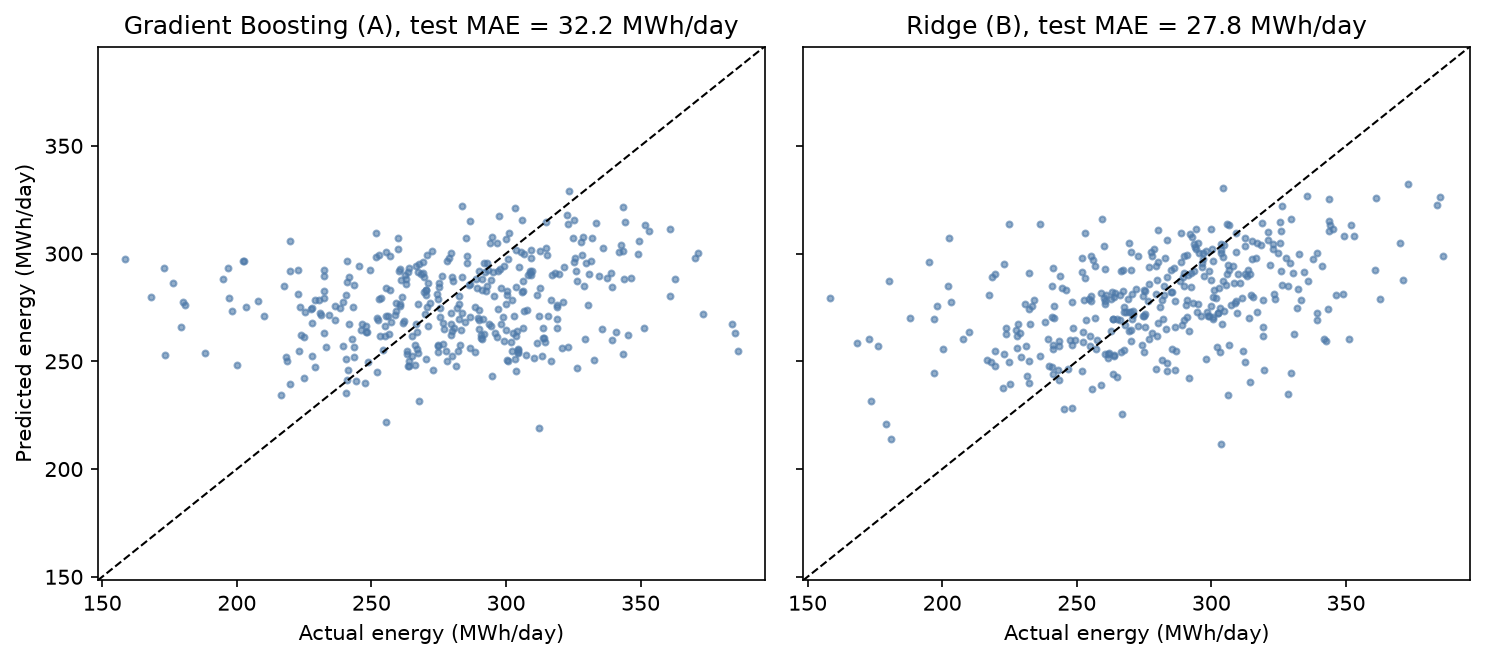

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=150, sharex=True, sharey=True)
limits = [test[TARGET].min() - 10, test[TARGET].max() + 10]

for ax, (name, pred) in zip(axes, [("Gradient Boosting (A)", pred_A), ("Ridge (B)", pred_B)]):
    mae = mean_absolute_error(test[TARGET], pred)
    ax.scatter(test[TARGET], pred, s=8, alpha=0.6, color="#4C78A8")
    ax.plot(limits, limits, "k--", linewidth=1)          # perfect prediction line (y = x)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel("Actual energy (MWh/day)")
    ax.set_title(f"{name}, test MAE = {mae:.1f} MWh/day")

axes[0].set_ylabel("Predicted energy (MWh/day)")
plt.tight_layout()
plt.savefig("fig_parity.png", bbox_inches="tight")
plt.show()